In [1]:
# Import packages
import pandas as pd
from os import listdir
from os.path import isfile, join
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Set variables
cells_for_multi_int = 3
indir = "../data_files/cluster_output/scRNAseq_bc_associations"
outdir = "../data_files/scRNAseq_bc_response"
vis_outdir = "../visualizations/scRNAseq_multi-int_eval"
full_dataset_response = "../data_files/amplicon_data/amplicon_full_dataset.csv"
untreated_cohort = "Untreated"
treated_cohorts = {"Carboplatin", "Paclitaxel"}

In [ ]:
def name_sample(csv_name):
    separated = csv_name.split("_")
    sample = "_".join(separated[:3])
    data_type = "_".join(separated[3:])
    return sample, data_type

def find_csvs(folder):
    csvs = [f for f in listdir(folder) if isfile(join(folder, f))]
    return csvs

def get_csv_data(outside_data):
    outside_df = pd.read_csv(outside_data).ffill()
    return outside_df

def pair_csvs(csv_list):
    samples = set()
    barcodes = []
    gfp = []
    for i in range(0, len(csv_list)):          
        sample, data_type = name_sample(csv_list[i])
        samples.add(sample)
        if data_type == "cell_GFP_umis_count.csv":
            gfp.append(data_type)
        else:
            barcodes.append(data_type)
    samples = list(samples)
    data = {"sample": samples, "barcode": barcodes, "GFP": gfp}
    data = pd.DataFrame(data)
    return data

def get_multilineage(barcode_csv, outdir):
    sample_name = barcode_csv.split("/")[-1]
    sample, data_type = name_sample(sample_name)
    barcodes_df = pd.read_csv(barcode_csv)
    barcodes_df.set_index("Unnamed: 0", drop = True, inplace = True)
    barcodes_df.index = barcodes_df.index.set_names([""])
    multi_lineage = []
    cells_w_each_num_lineage = {"1": 0, "2": 0, "3": 0, "4": 0, "5": 0, "6": 0, "7": 0, ">7":0}
    for i, row in barcodes_df.iterrows():
        lineage = []
        for column, value in row.items():
            barcode = column.split("_")[1]
            if value > 0:
                lineage.append(barcode)
        if len(lineage) > 1:
            multi_lineage.append(i) 
        if len(lineage) <= 7:
            cells_w_each_num_lineage[f"{len(lineage)}"] += 1
        else:
            cells_w_each_num_lineage[">7"] += 1  
    multi_df = barcodes_df.loc[multi_lineage]
    multi_df = multi_df.loc[:, (multi_df != 0).any(axis=0)]
    multi_df.to_csv(f"{outdir}/multi-lineage_cells/{sample}_multi-lineage.csv")
    return barcodes_df, multi_df, cells_w_each_num_lineage

def parse_model_csv(model, indir, outdir):
    csv_list = find_csvs(indir)
    csv_df = pair_csvs(csv_list)
    temp = csv_df["sample"].str.split("_", expand=True)
    csv_df["model"] = temp[0]
    model_df = csv_df.loc[csv_df["model"] == model]
    parsed = []
    dict_gfp_dfs = {}
    for i, row in model_df.iterrows(): 
        gfp_df = pd.read_csv(f"{indir}/{row['sample']}_{row['GFP']}").sort_values("Unnamed: 0")
        gfp_df["Unnamed: 0"] = gfp_df["Unnamed: 0"].str.strip()
        gfp_df.set_index("Unnamed: 0", drop = True, inplace = True)
        dict_gfp_dfs[row['sample']] = gfp_df

        sample_df = pd.read_csv(f"{indir}/{row['sample']}_{row['barcode']}")
        sample_df.set_index("Unnamed: 0", drop = True, inplace = True)
        sample_df.index = sample_df.index.set_names([""])

        for i2, row2 in sample_df.iterrows():
            bc_idx = row2.to_numpy().nonzero()
            bcs = list(row2.index[bc_idx])
            for bc in bcs:
                bc_data = {}
                bc_data["sample"] = row["sample"]
                bc_data["cellID"] = i2
                bc_data["barcode"] = bc.split("_")[1]
                parsed.append(bc_data)  

    parsed_df = pd.DataFrame(parsed) 
    return parsed_df, dict_gfp_dfs

def get_singlets_potential_multiplets(parsed_df):
    bc_per_cell_df = parsed_df.groupby(by=["sample", "cellID"]).size().reset_index(name="num_bcs")
    bc_per_cell_singlets = bc_per_cell_df.loc[bc_per_cell_df["num_bcs"] == 1]
    singlets_df = parsed_df.merge(bc_per_cell_singlets, how="right", on=["sample", "cellID"])[["sample", "cellID", "barcode"]]
    temp = singlets_df["sample"].str.split("_", expand=True)
    singlets_df["mouse"] = temp[1]
    singlets_df["barcode_status"] = "one barcode"
    singlets_df["original_barcode"] = singlets_df["barcode"]
    bc_per_cell_multiplets = bc_per_cell_df.loc[bc_per_cell_df["num_bcs"] > 1].reset_index(drop=True) 
    cell_bcs_multi_bc = []
    for i, row in bc_per_cell_multiplets.iterrows():
        curr_dict = {}
        sample = row["sample"]
        cell = row["cellID"]
        sample_cell = f"{sample} {cell}"
        cell_bcs_df = parsed_df.loc[(parsed_df["sample"] == sample) & (parsed_df["cellID"] == cell)]
        cell_bcs_list = cell_bcs_df["barcode"].to_list()
        curr_dict["cells"] = sample_cell
        curr_dict["barcodes"] = set(cell_bcs_list)
        cell_bcs_multi_bc.append(curr_dict)
    return singlets_df, cell_bcs_multi_bc

def get_multiplets_and_multi_int_v1(cell_bcs_multi_bc):
    multiplets = []
    multi_int_v1 = []
    for bc_dict in cell_bcs_multi_bc:
        full_bc_set_cell_counter = 0
        for dict_2 in cell_bcs_multi_bc:
            if bc_dict["barcodes"] == dict_2["barcodes"]:
                full_bc_set_cell_counter += 1
        if full_bc_set_cell_counter >= cells_for_multi_int:
            multi_int_v1.append(bc_dict)
        else:
            multiplets.append(bc_dict)
    return multiplets, multi_int_v1

def group_same_bcs(multi_int_v1):
    multi_int_combined = []
    grouped_bcs = []
    for curr_dict in multi_int_v1:
        new_dict = curr_dict.copy()
        new_dict["cells"] = [new_dict["cells"]]
        dicts_to_combine = []
        for idx, combo_dict in enumerate(multi_int_combined):
            if curr_dict["barcodes"] == combo_dict["barcodes"]:
                dicts_to_combine.append((idx, combo_dict))
        if len(dicts_to_combine) == 0:
            multi_int_combined.append(new_dict)
        else:
            indexes = []
            for pair in dicts_to_combine:
                indexes.append(pair[0])
                for cell in pair[1]["cells"]:
                    new_dict["cells"].append(cell)
            for index in sorted(indexes, reverse=True):
                del multi_int_combined[index]
            multi_int_combined.append(new_dict)
    for curr_dict in multi_int_combined:
        set_dict = {key: list(set(value)) for key, value in curr_dict.items()}
        set_dict["num cells"] = len(set_dict["cells"])
        grouped_bcs.append(set_dict)
    return grouped_bcs

def group_response_to_treatment(bc_dict, full_dataset_response, model):
    response_df = get_csv_data(full_dataset_response)
    response_df = response_df.loc[response_df["Tumor"] == model][["Tumor", "Cohort", "Mouse", '%GFP+', 'var_seq', "Clone Size", 'Treated Response']]
    consistency_per_mouse = []
    mice = set([mouse.split(" ")[0].split("_")[1] for mouse in bc_dict["cells"]])
    for mouse in mice:
        mouse_responses = []
        for bc in bc_dict["barcodes"]:
            bc_response = response_df.loc[(response_df["var_seq"] == bc) & (response_df["Mouse"] == mouse)]
            if bc_response.shape[0] > 0:
                mouse_responses.append(bc_response["Treated Response"].values[0])
        if len(set(mouse_responses)) == 1:
            consistency_per_mouse.append("Consistent")
        else:
            consistency_per_mouse.append("Inconsistent")
    if len(set(consistency_per_mouse)) == 1:
        return consistency_per_mouse[0]
    elif len(set(consistency_per_mouse)) == 0:
        return "Consistent"
    else:
        return "Inconsistent"

def eval_bc_sets(grouped_bcs, singlets_df, model):
    bc_eval_dict = []
    singlet_bc_cell_counts = singlets_df.groupby(["barcode"]).size().reset_index(name='num cells')
    if len(grouped_bcs) == 0:
        return "There are no suspected multi-integrations"
    for bc_dict in grouped_bcs:
        bc_info = {}
        bc_info["cells"] = bc_dict["cells"]
        bc_info["Response Consistency"] = group_response_to_treatment(bc_dict, full_dataset_response, model)
        bc_info["barcode set"] = bc_dict["barcodes"]
        bc_info["cells with set"] = bc_dict["num cells"]
        num_cells_each_bc_alone = []
        percentages = []
        for i in range(0, len(bc_dict["barcodes"])):
            bc_alone_df = singlet_bc_cell_counts.loc[singlet_bc_cell_counts["barcode"] == bc_dict["barcodes"][i]]["num cells"]
            if bc_alone_df.empty:
                bc_alone_count = 0
                percent_paired = 100
            else:
                bc_alone_count = bc_alone_df.values[0]
                percent_paired = (bc_info["cells with set"] / (bc_info["cells with set"] + bc_alone_count)) * 100
            bc_info[f"cells w barcode {i+1} alone"] = bc_alone_count
            bc_info[f"percent cells w bc {i+1} paired vs alone"] = percent_paired
            percentages.append(percent_paired)
            num_cells_each_bc_alone.append(bc_alone_count)
        bc_info["all cells w barcodes alone"] = num_cells_each_bc_alone
        bc_info["all percent paired"] = percentages
        bc_eval_dict.append(bc_info)
    set_eval_df = pd.DataFrame(bc_eval_dict).sort_values(by="cells with set", ascending=False).reset_index(drop=True)
    set_eval_df.to_csv(f"{outdir}/bc_set_eval/{model}_bc_set_eval.csv", index=False)
    return bc_eval_dict     

def classify_and_assign_bc(bc_eval_dict, ambiguous, model_amp_df, singlets_df, model):
    full_bc_assignments = []
    used_bcs = []
    final_multi_int_sets = []
    sorted_bc_eval_dict = sorted(bc_eval_dict, key=lambda d: d['cells with set'], reverse=True)
    singlets_dict = singlets_df.to_dict('records')
    bc_groups_combined = 0
    for ambiguous_cell in ambiguous:
        cell_info = {}
        sample_cell = ambiguous_cell["cells"].split(" ")
        cell_info["sample"] = sample_cell[0]
        cell_info["cellID"] = sample_cell[1]
        cell_info["barcode"] = "None"
        cell_info["barcode_status"] = "ambiguous"
        cell_info["original_barcode"] = ambiguous_cell["barcodes"]
        full_bc_assignments.append(cell_info)
    for bc_group in sorted_bc_eval_dict:
        found = any(bc in used_bcs for bc in bc_group["barcode set"])
        if bc_group["Response Consistency"] == "Inconsistent" or any(percent < 10 for percent in bc_group["all percent paired"]) or found:
            barcode = "None"
            barcode_status = "ambiguous"
        else:
            bc_groups_combined += 1
            bc_group_amplicon = model_amp_df.loc[model_amp_df["var_seq"].isin(bc_group["barcode set"])].sort_values(by=["Clone Size"], ascending=False).reset_index(drop=True)
            if bc_group_amplicon.shape[0] > 0:
                barcode = bc_group_amplicon.at[0,"var_seq"]
            else:
                barcode = bc_group["barcode set"][np.argmax(bc_group["all cells w barcodes alone"])]                       
            barcode_status = "multiple integration, multi-barcode"
            for bc in bc_group["barcode set"]:
                used_bcs.append(bc)
                for singlet_cell in singlets_dict:
                    if singlet_cell["barcode"] == str(bc).strip(): 
                        singlet_cell["barcode"] = str(barcode).strip()
                        singlet_cell["barcode_status"] = "multiple integration, one barcode"
            bc_set = {
                "barcode set": bc_group["barcode set"],
                "final barcode": barcode
            }
            final_multi_int_sets.append(bc_set)
        for cell in bc_group["cells"]:
            cell_info = {}
            sample_cell = cell.split(" ")
            cell_info["sample"] = str(sample_cell[0]).strip()
            cell_info["cellID"] = str(sample_cell[1]).strip()
            cell_info["barcode"] = barcode.strip()
            cell_info["barcode_status"] = barcode_status
            cell_info["original_barcode"] = [bc for bc in bc_group["barcode set"]]
            full_bc_assignments.append(cell_info)
    for singlet_cell in singlets_dict:
        full_bc_assignments.append(singlet_cell)
    final_bc_sets_df = pd.DataFrame(final_multi_int_sets)
    if final_bc_sets_df.shape[0] > 0:
        final_bc_sets_df.to_excel(f"{outdir}/multi-integrated_bcs/{model}_final_bc_multi-integration_sets.xlsx", index=False)
    return full_bc_assignments

def add_response_to_treatment(full_bc_assignments, amp_df):
    amp_df["sample"] = amp_df[["Tumor", "Mouse", "Cohort"]].astype(str).agg("_".join, axis=1)
    response_df = amp_df.rename(columns={"Treated Response": "treated_response", "Untreated Carboplatin Response": "untreated_carboplatin_response", "Untreated Paclitaxel Response": "untreated_paclitaxel_response", "var_seq": "barcode", "Treated Response Consistency": "consistency"})
    response_df = response_df[["barcode", "sample", "treated_response", "untreated_carboplatin_response", "untreated_paclitaxel_response", "consistency"]]

    full_bc_assignments_df = pd.DataFrame(full_bc_assignments)
    full_bc_assignments_response_df = pd.merge(full_bc_assignments_df, response_df, how="left", on=["sample", "barcode"]).fillna("Unknown")

    return full_bc_assignments_response_df

def get_treated_and_untreated_bcs(amp_df, model):
    model_amp_df = amp_df.loc[amp_df["Tumor"] == model]
    cohorts_per_bc = model_amp_df.groupby("var_seq")["Cohort"].agg(set)
    in_both = cohorts_per_bc.apply(lambda cohorts: untreated_cohort in cohorts and len(cohorts & treated_cohorts) > 0)
    return set(cohorts_per_bc.index[in_both])


def split_samples_fill_all_cells(full_bc_assignments_response_df, dict_gfp_dfs, outdir, treated_and_untreated_bcs):
    sample_dfs = []
    for sample_name, sample_df in dict_gfp_dfs.items():
        sample_df.index.name = None
        
        sample_bcs = full_bc_assignments_response_df.copy()
        sample_bcs = sample_bcs.loc[sample_bcs["sample"] == sample_name]
        sample_bcs = sample_bcs[["cellID", "barcode", "barcode_status", "original_barcode", "treated_response", "untreated_carboplatin_response", "untreated_paclitaxel_response", "consistency"]].set_index("cellID", drop=True)
        
        merged_df = pd.merge(sample_df, sample_bcs, how="left", left_index=True, right_index=True)
        merged_df["barcode"] = merged_df["barcode"].fillna(value="None")
        merged_df["treated_response"] = merged_df["treated_response"].fillna(value="Unknown")
        merged_df["untreated_carboplatin_response"] = merged_df["untreated_carboplatin_response"].fillna(value="Unknown")
        merged_df["untreated_paclitaxel_response"] = merged_df["untreated_paclitaxel_response"].fillna(value="Unknown")
        merged_df["barcode_status"] = merged_df["barcode_status"].fillna(value="no barcode")
        merged_df["original_barcode"] = merged_df["original_barcode"].fillna(value="None")
        merged_df["consistency"] = merged_df["consistency"].fillna(value="Unknown")
        merged_df["treated_and_untreated"] = merged_df["barcode"].isin(treated_and_untreated_bcs)
        merged_df = merged_df[["barcode", "barcode_status", "original_barcode", "treated_response", "untreated_carboplatin_response", "untreated_paclitaxel_response", "consistency", "treated_and_untreated"]]
        merged_df.index.name = "cellID"

        print(f"Saving final bc csv for {sample_name}")
        merged_df.to_csv(f"{outdir}/sample_final_bc_response/{sample_name}_final_bc_asignments.csv")

        mouse = sample_name.split("_")[1]
        merged_with_mouse = merged_df.add_prefix(f"{mouse}_", axis = 0)
        sample_dfs.append(merged_with_mouse)  
    
    model = sample_name.split("_")[0]
    full_model_df = pd.concat(sample_dfs, axis=0)
    full_model_df.to_csv(f"{outdir}/model_final_bc_response/{model}_final_bc_asignments.csv")

def graph_eval_ungrouped(multi_int_v1, model):
    multi_df = pd.DataFrame(multi_int_v1)
    multi_df["sample"] = multi_df["cells"].apply(lambda x: x.split(" ")[0])
    multi_df["cell"] = multi_df["cells"].apply(lambda x: x.split(" ")[1])
    barcodes = []
    for i, row in multi_df.iterrows():
        for x in row["barcodes"]:
            barcodes.append(x)
    barcodes = list(set(barcodes))
    unique_bcs_dict = {k: v for k, v in zip(barcodes, range(1, len(barcodes)+1))}
    multi_df["BC_ID"] = multi_df["barcodes"].apply(lambda x: list(str(unique_bcs_dict[i]) for i in x))
    multi_df["BC_ID"] = multi_df["BC_ID"].apply(lambda x: ("_").join(x))
    multi_df = multi_df[["sample", "cell", "BC_ID"]]

    multi_df_grouped = multi_df.groupby("BC_ID").count()["cell"]

    ax = multi_df_grouped.plot.bar(figsize=(15,5))
    ax.set_title(f"{model} Ungrouped Barcode Sets",color='black')
    ax.set_xlabel("Barcode Set")
    ax.set_ylabel("Number of Cells")
    for container in ax.containers:
        ax.bar_label(container)
    return ax, unique_bcs_dict

def run_full_bc_assignment(model, indir, outdir, vis_outdir, full_dataset_response):
    parsed_df, dict_gfp_dfs = parse_model_csv(model, indir, outdir)
    singlets_df, cell_bcs_multi_bc = get_singlets_potential_multiplets(parsed_df)
    ambiguous, multi_int_v1 = get_multiplets_and_multi_int_v1(cell_bcs_multi_bc) 

    graph_eval_ungrouped(multi_int_v1, model) 
    plt.savefig(f"{vis_outdir}/{model}_ungrouped_eval.svg")
    plt.show()

    grouped_bcs = group_same_bcs(multi_int_v1)  
    bc_eval_dict = eval_bc_sets(grouped_bcs, singlets_df, model)

    amp_df = get_csv_data(full_dataset_response)
    model_amp_df = amp_df.loc[amp_df["Tumor"] == model][["Tumor", "Cohort", "Mouse", '%GFP+', 'var_seq', 'Clone Size', 'Tumor', 'BC']]
    
    full_bc_assignments = classify_and_assign_bc(bc_eval_dict, ambiguous, model_amp_df, singlets_df, model)

    full_bc_assignments_response_df = add_response_to_treatment(full_bc_assignments, amp_df)
    treated_and_untreated_bcs = get_treated_and_untreated_bcs(amp_df, model)
    
    split_samples_fill_all_cells(full_bc_assignments_response_df, dict_gfp_dfs, outdir, treated_and_untreated_bcs)
    
def describe_data(indir, outdir):
    csv_list = find_csvs(indir)
    csvs_df = pair_csvs(csv_list)
    sample_meta = []
    for i, row in csvs_df.iterrows():
        sample_data = {}

        barcodes_df, multi_df, cells_w_each_num_lineage = get_multilineage(f"{indir}/{row['sample']}_{row['barcode']}", outdir) 
        gfp_df = pd.read_csv(f"{indir}/{row['sample']}_{row['GFP']}")
        num_bc_cells = barcodes_df.shape[0]
        total_cells = gfp_df.shape[0]
        percent_bc_cells = (num_bc_cells / total_cells) * 100
        num_multi = multi_df.shape[0]
        percent_of_bc_multi = (num_multi / num_bc_cells) * 100
        percent_of_total_multi = (num_multi / total_cells) * 100
        sample_split = row["sample"].split("_")

        sample_data["sample"] = row["sample"]
        sample_data["model"] = sample_split[0]
        sample_data["cohort"] = sample_split[2]
        sample_data["mouse"] = sample_split[1]
        sample_data["total cells"] = total_cells
        sample_data["bc cells"] = num_bc_cells
        sample_data["un-bc cells"] = total_cells - num_bc_cells
        sample_data["percent bc cells"] = round(percent_bc_cells, 3)
        sample_data["expected barcoded doublets"] = 0.08 * num_bc_cells
        sample_data["cells w multiple bc"] = num_multi
        sample_data["percent bc cells >1 bc"] = round(percent_of_bc_multi, 3)
        sample_data["percent total cells >1 bc"] = round(percent_of_total_multi, 3)
        sample_data["1 bc"] = cells_w_each_num_lineage["1"]
        sample_data["2 bc"] = cells_w_each_num_lineage["2"]
        sample_data["3 bc"] = cells_w_each_num_lineage["3"]
        sample_data["4 bc"] = cells_w_each_num_lineage["4"]
        sample_data["5 bc"] = cells_w_each_num_lineage["5"]
        sample_data["6 bc"] = cells_w_each_num_lineage["6"]
        sample_data["7 bc"] = cells_w_each_num_lineage["7"]
        sample_data[">7 bc"] = cells_w_each_num_lineage[">7"]

        sample_meta.append(sample_data)

    meta_df = pd.DataFrame(sample_meta)
    meta_df.to_csv(f"{outdir}/scRNAseq_all_samples_bc_stats.csv")
    return meta_df
    

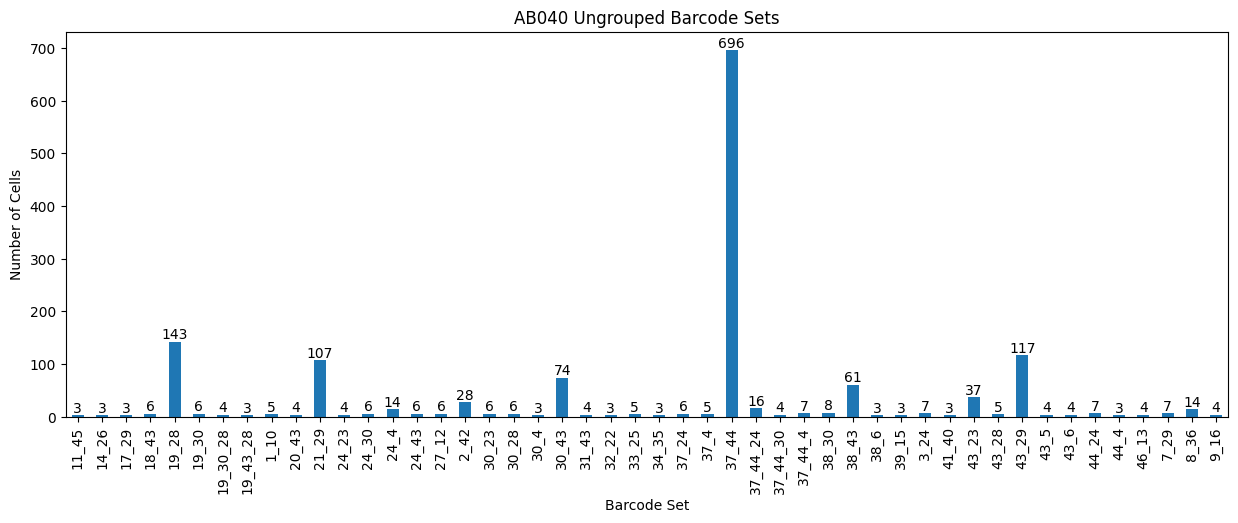

Saving final bc csv for AB040_M00021201_Untreated
Saving final bc csv for AB040_M00021193_Paclitaxel
Saving final bc csv for AB040_M00021191_Paclitaxel
Saving final bc csv for AB040_M00021194_Paclitaxel
Saving final bc csv for AB040_M00021192_Carboplatin
Saving final bc csv for AB040_M00021202_Untreated
Saving final bc csv for AB040_AN21-021169_Primary
Saving final bc csv for AB040_M00021200_Carboplatin
Saving final bc csv for AB040_M00021185_Carboplatin
Saving final bc csv for AB040_M00021195_Untreated


In [4]:
run_full_bc_assignment("AB040", indir, outdir, vis_outdir, full_dataset_response)    

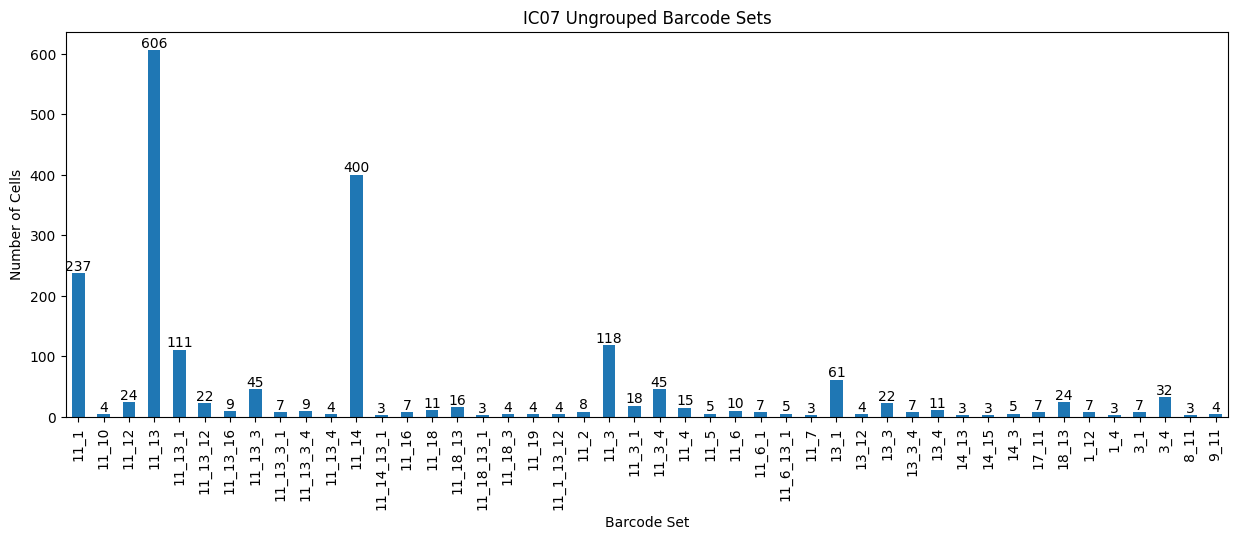

Saving final bc csv for IC07_M00021196_Untreated
Saving final bc csv for IC07_M00021197_Carboplatin
Saving final bc csv for IC07_AN21-021162_Primary
Saving final bc csv for IC07_M00021199_Paclitaxel
Saving final bc csv for IC07_M00021190_Carboplatin
Saving final bc csv for IC07_M00021189_Paclitaxel
Saving final bc csv for IC07_M00021186_Carboplatin
Saving final bc csv for IC07_M00021198_Paclitaxel
Saving final bc csv for IC07_M00021188_Untreated


In [5]:
run_full_bc_assignment("IC07", indir, outdir, vis_outdir, full_dataset_response)    

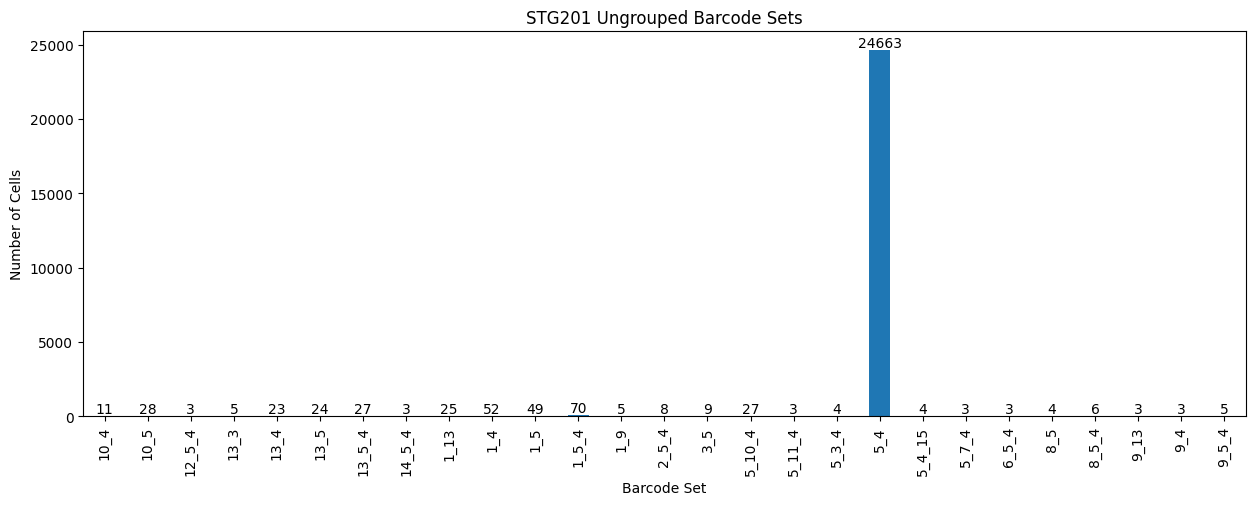

Saving final bc csv for STG201_M00021176_Paclitaxel
Saving final bc csv for STG201_M00021181_Untreated
Saving final bc csv for STG201_M00021183_Paclitaxel
Saving final bc csv for STG201_M00021179_Untreated
Saving final bc csv for STG201_M00021182_Carboplatin
Saving final bc csv for STG201_AN21-021165_Primary
Saving final bc csv for STG201_M00021178_Paclitaxel
Saving final bc csv for STG201_M00021180_Untreated
Saving final bc csv for STG201_M00021177_Carboplatin


In [6]:
run_full_bc_assignment("STG201", indir, outdir, vis_outdir, full_dataset_response)    

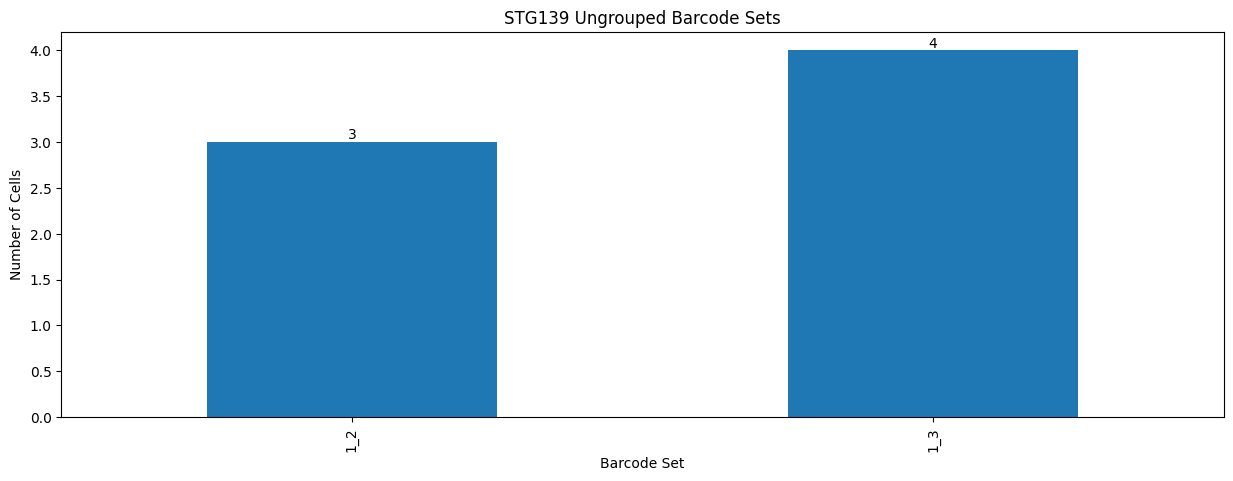

Saving final bc csv for STG139_M00021170_Paclitaxel
Saving final bc csv for STG139_M00021171_Untreated
Saving final bc csv for STG139_M00021166_Untreated
Saving final bc csv for STG139_M00021169_Carboplatin
Saving final bc csv for STG139_AN21-021161_Primary
Saving final bc csv for STG139_M00021174_Carboplatin


In [7]:
run_full_bc_assignment("STG139", indir, outdir, vis_outdir, full_dataset_response)    